In [ ]:
!zip -r unet_Our_Data_mod1_outputs.zip /content/unet_Our_data_mod1_outputs

  adding: content/unet_Our_data_mod1_outputs/ (stored 0%)
  adding: content/unet_Our_data_mod1_outputs/predictions/ (stored 0%)
  adding: content/unet_Our_data_mod1_outputs/predictions/visualizations/ (stored 0%)
  adding: content/unet_Our_data_mod1_outputs/predictions/visualizations/image10_prediction.png (deflated 13%)
  adding: content/unet_Our_data_mod1_outputs/predictions/visualizations/image7_prediction.png (deflated 12%)
  adding: content/unet_Our_data_mod1_outputs/predictions/visualizations/image14_prediction.png (deflated 11%)
  adding: content/unet_Our_data_mod1_outputs/predictions/masks/ (stored 0%)
  adding: content/unet_Our_data_mod1_outputs/predictions/masks/image14_predicted_mask.png (deflated 11%)
  adding: content/unet_Our_data_mod1_outputs/predictions/masks/image7_predicted_mask.png (deflated 8%)
  adding: content/unet_Our_data_mod1_outputs/predictions/masks/image10_predicted_mask.png (deflated 11%)
  adding: content/unet_Our_data_mod1_outputs/models/ (stored 0%)
  ad

In [1]:
!unzip -q /content/Our_data.zip -d /content/

In [2]:
import os
import glob
import random
import json
import shutil
import csv
from pathlib import Path
from contextlib import redirect_stdout
from io import StringIO

import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from sklearn.model_selection import train_test_split


IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
SEED = 42

IMAGE_DIR = "/content/Our_data/images"
MASK_DIR = "/content/Our_data/masks"
OUTPUT_DIR = "/content/unet_Our_data_mod1_outputs"

MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predictions")
PREDICTION_MASK_DIR = os.path.join(PREDICTION_DIR, "masks")
PREDICTION_VIS_DIR = os.path.join(PREDICTION_DIR, "visualizations")
METRIC_DIR = os.path.join(OUTPUT_DIR, "metrics")
SPLIT_DIR = os.path.join(OUTPUT_DIR, "splits")
SNAPSHOT_IMAGE_DIR = os.path.join(OUTPUT_DIR, "dataset_snapshot", "images")
SNAPSHOT_MASK_DIR = os.path.join(OUTPUT_DIR, "dataset_snapshot", "masks")

for directory in [
    OUTPUT_DIR,
    MODEL_DIR,
    PLOT_DIR,
    PREDICTION_MASK_DIR,
    PREDICTION_VIS_DIR,
    METRIC_DIR,
    SPLIT_DIR,
    SNAPSHOT_IMAGE_DIR,
    SNAPSHOT_MASK_DIR
]:
    os.makedirs(directory, exist_ok=True)

tf.random.set_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)

if not os.path.isdir(IMAGE_DIR):
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")
if not os.path.isdir(MASK_DIR):
    raise FileNotFoundError(f"Mask directory not found: {MASK_DIR}")

print("Images:", len(os.listdir(IMAGE_DIR)))
print("Masks:", len(os.listdir(MASK_DIR)))
print("Output directory:", OUTPUT_DIR)

Images: 16
Masks: 16
Output directory: /content/unet_Our_data_mod1_outputs


In [3]:
def get_pairs(image_dir, mask_dir):
    image_paths = []
    for ext in ["jpg", "jpeg", "png", "bmp", "tif", "tiff"]:
        image_paths.extend(glob.glob(os.path.join(image_dir, f"*.{ext}")))

    image_paths = sorted(image_paths)

    mask_map = {}
    for ext in ["jpg", "jpeg", "png", "bmp", "tif", "tiff"]:
        for path in glob.glob(os.path.join(mask_dir, f"*.{ext}")):
            stem = os.path.splitext(os.path.basename(path))[0]
            mask_map[stem] = path

    pairs = []
    for img_path in image_paths:
        stem = os.path.splitext(os.path.basename(img_path))[0]
        if stem in mask_map:
            pairs.append((img_path, mask_map[stem]))
        else:
            print(f"Warning: no mask found for {img_path}")

    return pairs


def load_image_mask(img_path, mask_path):
    img = cv2.imread(img_path.decode(), cv2.IMREAD_COLOR)
    if img is None:
        raise ValueError(f"Could not read image: {img_path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)
    img = img.astype(np.float32) / 255.0

    mask = cv2.imread(mask_path.decode(), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")
    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    mask = (mask > 127).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    return img, mask


def tf_load_image_mask(img_path, mask_path):
    img, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32]
    )
    img.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return img, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    k = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    image = tf.image.rot90(image, k)
    mask = tf.image.rot90(mask, k)

    return image, mask


pairs = get_pairs(IMAGE_DIR, MASK_DIR)

if not pairs:
    raise ValueError("No matching image-mask pairs were found.")

print("Total paired samples:", len(pairs))

for img_path, mask_path in pairs[:3]:
    print(img_path)
    print(mask_path)

Total paired samples: 16
/content/Our_data/images/image1.jpg
/content/Our_data/masks/image1.png
/content/Our_data/images/image10.jpg
/content/Our_data/masks/image10.png
/content/Our_data/images/image11.png
/content/Our_data/masks/image11.png


In [4]:
train_pairs, remaining_pairs = train_test_split(
    pairs,
    test_size=0.30,
    random_state=SEED
)

val_pairs, test_pairs = train_test_split(
    remaining_pairs,
    test_size=0.50,
    random_state=SEED
)


def make_dataset(sample_pairs, training=True):
    img_paths = [pair[0] for pair in sample_pairs]
    mask_paths = [pair[1] for pair in sample_pairs]

    ds = tf.data.Dataset.from_tensor_slices((img_paths, mask_paths))
    if training:
        ds = ds.shuffle(
            buffer_size=len(sample_pairs),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(tf_load_image_mask, num_parallel_calls=tf.data.AUTOTUNE)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_pairs, training=True)
val_ds = make_dataset(val_pairs, training=False)
test_ds = make_dataset(test_pairs, training=False)

print("Train samples:", len(train_pairs))
print("Validation samples:", len(val_pairs))
print("Test samples:", len(test_pairs))
print("Total samples:", len(train_pairs) + len(val_pairs) + len(test_pairs))

split_rows = []
for split_name, split_pairs in [
    ("train", train_pairs),
    ("validation", val_pairs),
    ("test", test_pairs)
]:
    for img_path, mask_path in split_pairs:
        split_rows.append({
            "split": split_name,
            "image_path": img_path,
            "mask_path": mask_path,
            "image_filename": os.path.basename(img_path),
            "mask_filename": os.path.basename(mask_path)
        })

pd.DataFrame(split_rows).to_csv(
    os.path.join(SPLIT_DIR, "split_manifest.csv"),
    index=False
)

split_counts = {
    "total": len(pairs),
    "train": len(train_pairs),
    "validation": len(val_pairs),
    "test": len(test_pairs),
    "seed": SEED,
    "ratios": {
        "train": 0.70,
        "validation": 0.15,
        "test": 0.15
    }
}

with open(os.path.join(SPLIT_DIR, "split_counts.json"), "w") as file:
    json.dump(split_counts, file, indent=4)

for img_path, mask_path in pairs:
    shutil.copy2(img_path, os.path.join(SNAPSHOT_IMAGE_DIR, os.path.basename(img_path)))
    shutil.copy2(mask_path, os.path.join(SNAPSHOT_MASK_DIR, os.path.basename(mask_path)))

Train samples: 11
Validation samples: 2
Test samples: 3
Total samples: 16


In [6]:
def dice_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (
        tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth
    )


def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)


def iou_coef(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    return x


def down_block(x, filters):
    c = conv_block(x, filters)
    p = layers.MaxPool2D((2, 2))(c)
    p = layers.Dropout(0.2)(p)
    return c, p


def resize_to_ref(tensor, ref, name=None):
    return layers.Lambda(
        lambda t: tf.image.resize(t[0], tf.shape(t[1])[1:3], method="bilinear"),
        name=name
    )([tensor, ref])


def project_and_resize(skip, ref, filters):
    skip = layers.Conv2D(filters, 1, padding="same", kernel_initializer="he_normal")(skip)
    skip = layers.BatchNormalization()(skip)
    skip = layers.ReLU()(skip)
    skip = resize_to_ref(skip, ref)
    return skip


def up_block(x, skips, filters):
    x = layers.UpSampling2D((2, 2), interpolation="bilinear")(x)
    x = layers.Conv2D(filters, 3, padding="same", kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    fused = [x]

    for skip_tensor in skips:
        if skip_tensor is not None:
            skip_tensor = project_and_resize(skip_tensor, x, filters)
            fused.append(skip_tensor)

    if len(fused) > 1:
        x = layers.Concatenate()(fused)

    x = layers.Dropout(0.2)(x)
    x = conv_block(x, filters)
    return x


def build_unet(input_shape=(256, 256, 3)):
    inputs = layers.Input(shape=input_shape)

    c1, p1 = down_block(inputs, 32)
    c2, p2 = down_block(p1, 64)
    c3, p3 = down_block(p2, 128)
    c4, p4 = down_block(p3, 256)

    bottleneck = conv_block(p4, 512)

    u1 = up_block(bottleneck, [c4], 256)
    u2 = up_block(u1, [c3, c4], 128)
    u3 = up_block(u2, [c2, c3], 64)
    u4 = up_block(u3, [c1, c2], 32)

    outputs = layers.Conv2D(1, 1, activation="sigmoid")(u4)

    model = Model(inputs, outputs, name="UNet_MultiSkip_Resized")
    return model


model = build_unet(input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss=dice_loss,
    metrics=[
        "accuracy",
        dice_coef,
        iou_coef,
        tf.keras.metrics.Precision(name="precision", thresholds=0.5),
        tf.keras.metrics.Recall(name="recall", thresholds=0.5)
    ]
)

summary_lines = []
model.summary(print_fn=lambda line: summary_lines.append(line))
with open(os.path.join(MODEL_DIR, "model_summary.txt"), "w") as file:
    file.write("\n".join(summary_lines))
model.summary()
print("Model parameters:", model.count_params())

Model: "UNet_MultiSkip_Resized"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_30 (Conv2D)  │ (None, 256, 256,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_30[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_29 (ReLU)     │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_31 (Conv2D)  │ (None, 256, 256,  │      9,248 │ re_lu_29[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 256, 256,  │        128 │ conv2d_31[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_30 (ReLU)     │ (None, 256, 256,  │          0 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ re_lu_30[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_8 (Dropout) │ (None, 128, 128,  │          0 │ max_pooling2d_4[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, 128, 128,  │     18,496 │ dropout_8[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_31 (ReLU)     │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_33 (Conv2D)  │ (None, 128, 128,  │     36,928 │ re_lu_31[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 128, 128,  │        256 │ conv2d_33[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_32 (ReLU)     │ (None, 128, 128,  │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ re_lu_32[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_9 (Dropout) │ (None, 64, 64,    │          0 │ max_pooling2d_5[

 Total params: 8,971,297 (34.22 MB)

 Trainable params: 8,963,041 (34.19 MB)

 Non-trainable params: 8,256 (32.25 KB)

Model parameters: 8971297


In [7]:
best_model_path = os.path.join(MODEL_DIR, "best_unet.keras")
final_model_path = os.path.join(MODEL_DIR, "final_unet.keras")

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        best_model_path,
        monitor="val_dice_coef",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_dice_coef",
        mode="max",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_dice_coef",
        mode="max",
        factor=0.5,
        patience=4,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks
)

model.save(final_model_path)

history_df = pd.DataFrame(history.history)
history_df.insert(0, "epoch", np.arange(1, len(history_df) + 1))
history_df.to_csv(
    os.path.join(METRIC_DIR, "training_history.csv"),
    index=False
)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10s/step - accuracy: 0.6232 - dice_coef: 0.6587 - iou_coef: 0.4920 - loss: 0.3405 - precision: 0.6677 - recall: 0.8527  
Epoch 1: val_dice_coef improved from None to 0.57931, saving model to /content/unet_Our_data_mod1_outputs/models/best_unet.keras

Epoch 1: finished saving model to /content/unet_Our_data_mod1_outputs/models/best_unet.keras
6/6 ━━━━━━━━━━━━━━━━━━━━ 134s 11s/step - accuracy: 0.6416 - dice_coef: 0.6647 - iou_coef: 0.4988 - loss: 0.3305 - precision: 0.6841 - recall: 0.8642 - val_accuracy: 0.5644 - val_dice_coef: 0.5793 - val_iou_coef: 0.4078 - val_loss: 0.4207 - val_precision: 0.5605 - val_recall: 0.9714 - learning_rate: 1.0000e-04
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step - accuracy: 0.6644 - dice_coef: 0.6812 - iou_coef: 0.5191 - loss: 0.3192 - precision: 0.6909 - recall: 0.8764
Epoch 2: val_dice_coef did not improve from 0.57931
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 247ms/step - accuracy: 0.6857 - dice_coef: 0.6983 - iou_coef: 0.53

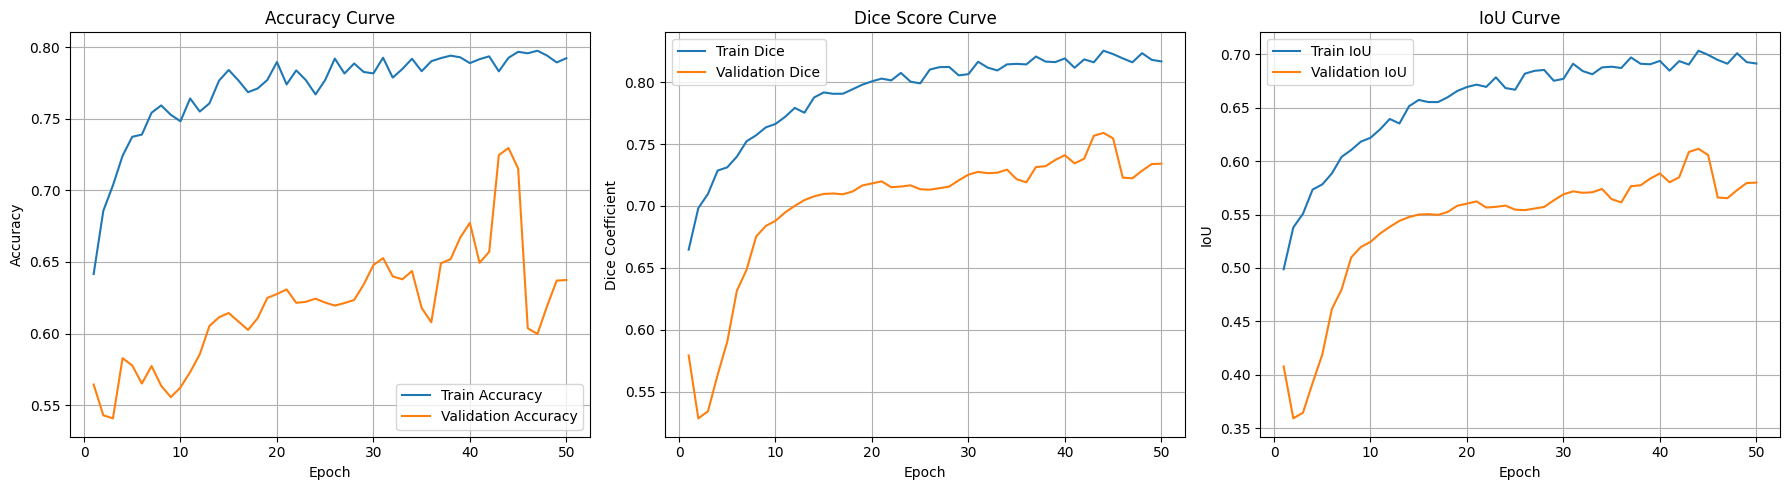

In [8]:
def plot_training_curves(training_history):
    hist = training_history.history
    epochs_range = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(18, 5))

    plt.subplot(1, 3, 1)
    plt.plot(epochs_range, hist["accuracy"], label="Train Accuracy")
    plt.plot(epochs_range, hist["val_accuracy"], label="Validation Accuracy")
    plt.title("Accuracy Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 2)
    plt.plot(epochs_range, hist["dice_coef"], label="Train Dice")
    plt.plot(epochs_range, hist["val_dice_coef"], label="Validation Dice")
    plt.title("Dice Score Curve")
    plt.xlabel("Epoch")
    plt.ylabel("Dice Coefficient")
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 3, 3)
    plt.plot(epochs_range, hist["iou_coef"], label="Train IoU")
    plt.plot(epochs_range, hist["val_iou_coef"], label="Validation IoU")
    plt.title("IoU Curve")
    plt.xlabel("Epoch")
    plt.ylabel("IoU")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.savefig(
        os.path.join(PLOT_DIR, "training_curves.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()


plot_training_curves(history)

2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 4s/step - accuracy: 0.7427 - dice_coef: 0.8042 - iou_coef: 0.6763 - loss: 0.2151 - precision: 0.7046 - recall: 0.9381
Final test results:
accuracy: 0.7427
dice_coef: 0.8042
iou_coef: 0.6763
loss: 0.2151
precision: 0.7046
recall: 0.9381


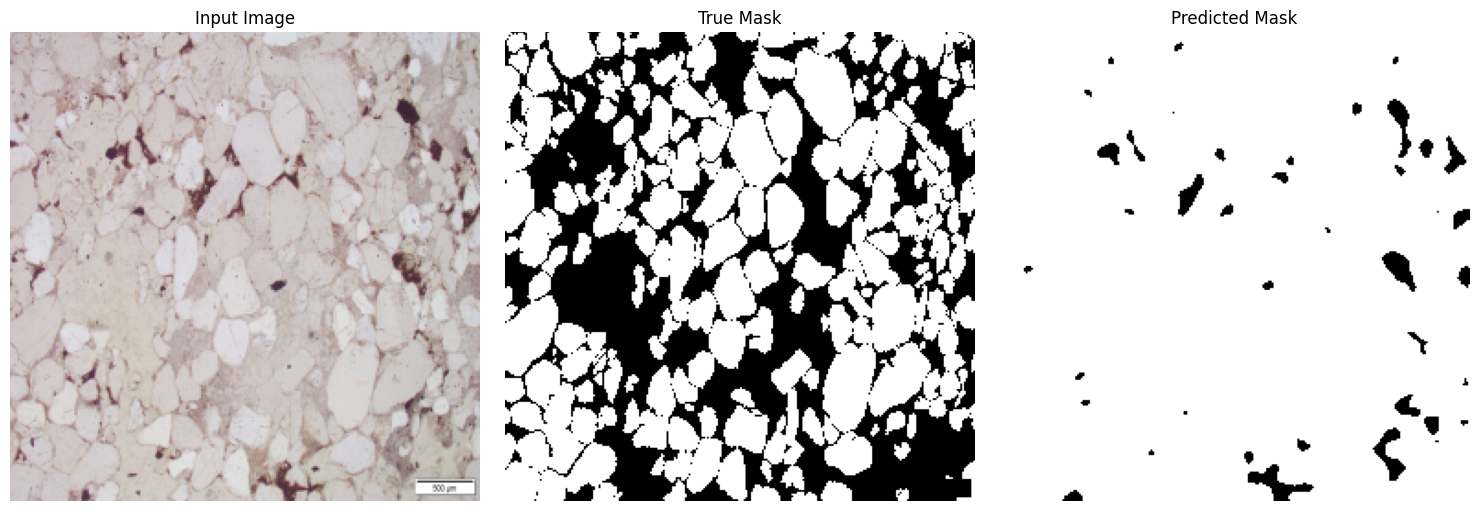

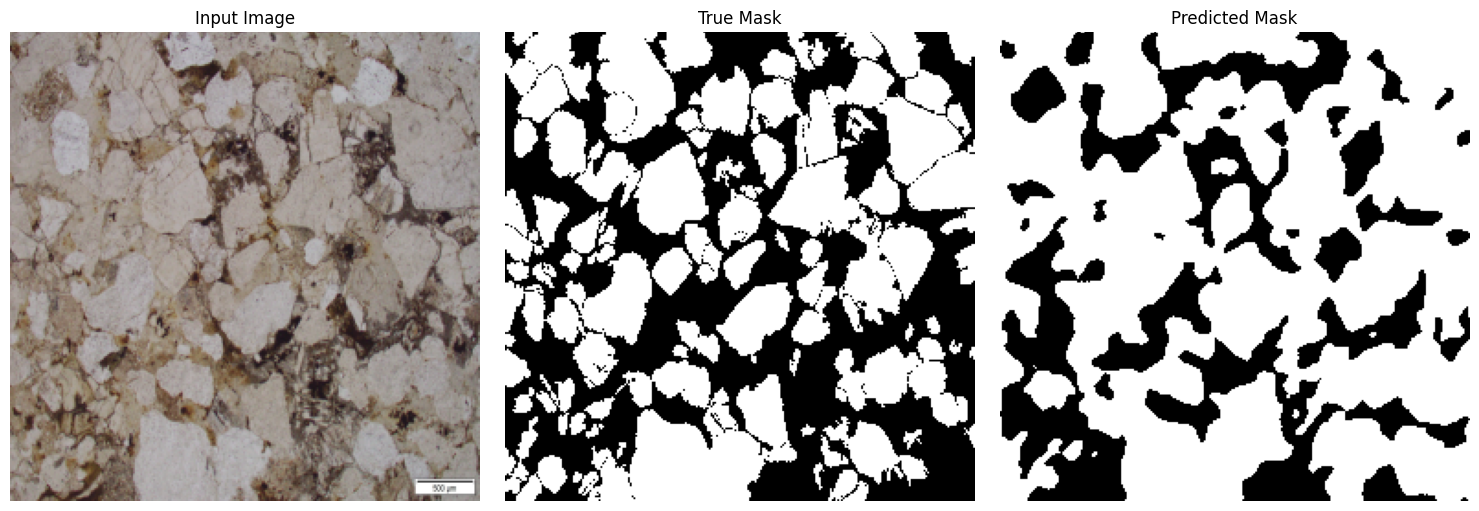

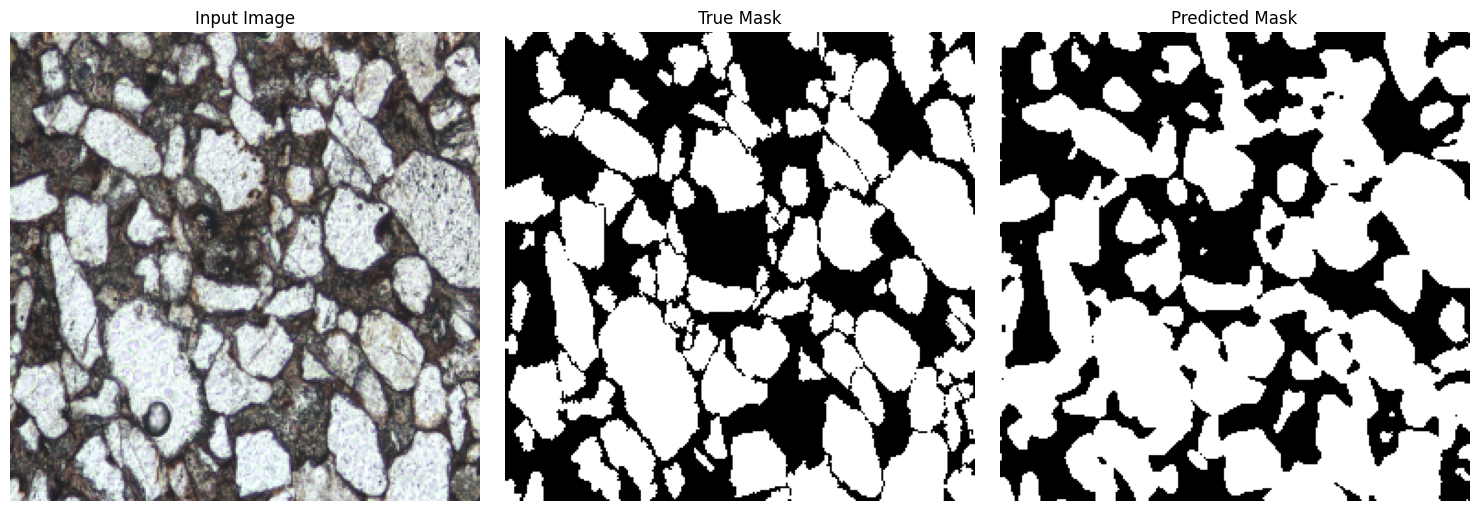

Per-sample test metrics:


,image,dice,iou,precision,recall
0,image10.jpg,0.750255,0.600326,0.603067,0.992485
1,image7.jpg,0.784651,0.645618,0.701203,0.890643
2,image14.png,0.900269,0.818627,0.874642,0.927443


In [9]:
test_results = model.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

test_results = {key: float(value) for key, value in test_results.items()}

with open(os.path.join(METRIC_DIR, "test_metrics.json"), "w") as file:
    json.dump(test_results, file, indent=4)

print("Final test results:")
for metric_name, metric_value in test_results.items():
    print(f"{metric_name}: {metric_value:.4f}")


def show_prediction(model, pair, save_path=None):
    img_path, mask_path = pair
    img, mask = load_image_mask(img_path.encode(), mask_path.encode())

    pred = model.predict(np.expand_dims(img, axis=0), verbose=0)[0]
    pred_mask = (pred > 0.5).astype(np.uint8)

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title("Input Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask.squeeze(), cmap="gray")
    plt.title("True Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pred_mask.squeeze(), cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close()

    true_binary = mask.squeeze().astype(np.uint8)
    pred_binary = pred_mask.squeeze().astype(np.uint8)

    intersection = np.logical_and(true_binary, pred_binary).sum()
    dice = (2.0 * intersection + 1e-7) / (
        true_binary.sum() + pred_binary.sum() + 1e-7
    )

    union = np.logical_or(true_binary, pred_binary).sum()
    iou = (intersection + 1e-7) / (union + 1e-7)

    # Pixel-wise precision and recall for this image.
    true_positives = intersection
    false_positives = np.logical_and(true_binary == 0, pred_binary == 1).sum()
    false_negatives = np.logical_and(true_binary == 1, pred_binary == 0).sum()

    precision_denominator = true_positives + false_positives
    recall_denominator = true_positives + false_negatives

    precision = (
        true_positives / precision_denominator
        if precision_denominator > 0 else 0.0
    )
    recall = (
        true_positives / recall_denominator
        if recall_denominator > 0 else 0.0
    )

    return dice, iou, precision, recall, pred_mask


per_sample_results = []

for index, pair in enumerate(test_pairs, start=1):
    image_name = os.path.basename(pair[0])
    image_stem = os.path.splitext(image_name)[0]
    visualization_path = os.path.join(
        PREDICTION_VIS_DIR,
        f"{image_stem}_prediction.png"
    )
    mask_path = os.path.join(
        PREDICTION_MASK_DIR,
        f"{image_stem}_predicted_mask.png"
    )

    dice, iou, precision, recall, predicted_mask = show_prediction(
        model,
        pair,
        save_path=visualization_path
    )

    cv2.imwrite(mask_path, predicted_mask.squeeze() * 255)

    per_sample_results.append({
        "image": image_name,
        "dice": float(dice),
        "iou": float(iou),
        "precision": float(precision),
        "recall": float(recall)
    })

per_sample_df = pd.DataFrame(per_sample_results)
per_sample_df.to_csv(
    os.path.join(METRIC_DIR, "per_sample_test_metrics.csv"),
    index=False
)

print("Per-sample test metrics:")
display(per_sample_df)

In [10]:
experiment_summary = {
    "model_name": model.name,
    "image_size": list(IMG_SIZE),
    "batch_size": BATCH_SIZE,
    "epochs_requested": EPOCHS,
    "epochs_completed": len(history.history["loss"]),
    "seed": SEED,
    "total_samples": len(pairs),
    "train_samples": len(train_pairs),
    "validation_samples": len(val_pairs),
    "test_samples": len(test_pairs),
    "best_validation_dice": float(max(history.history["val_dice_coef"])),
    "test_metrics": test_results,
    "output_directory": OUTPUT_DIR
}

with open(os.path.join(OUTPUT_DIR, "experiment_summary.json"), "w") as file:
    json.dump(experiment_summary, file, indent=4)

readme_text = (
    "Rock segmentation experiment outputs\n"
    "\n"
    "models/: best and final Keras models plus model summary\n"
    "plots/: training curves\n"
    "predictions/masks/: predicted binary test masks\n"
    "predictions/visualizations/: input, ground-truth and predicted-mask comparisons\n"
    "metrics/: training history, aggregate test metrics and per-sample test metrics\n"
    "splits/: train, validation and test split manifest and counts\n"
    "dataset_snapshot/: copies of the paired source images and masks\n"
)

with open(os.path.join(OUTPUT_DIR, "README.txt"), "w") as file:
    file.write(readme_text)

print("All experiment files saved to:", OUTPUT_DIR)

All experiment files saved to: /content/unet_Our_data_mod1_outputs
